### Task 1: Bidirectional Transformer Encoder for News Topic Classification from Scratch

In [1]:
import csv
import math
import re
from collections import Counter
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# Set random seeds for reproducibility
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cpu


#### 1. Tokenizer and Dataset Creation

In [2]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
    return text.split()

# Build Vocabulary from train.csv
def build_vocab(filepath, max_vocab_size=15000):
    counter = Counter()
    with open(filepath, 'r', encoding='utf-8') as f:
        reader = csv.reader(f)
        next(reader) # skip header if exists
        for row in reader:
            if len(row) >= 3:
                # class, title, description
                text = clean_text(row[1] + " " + row[2])
                counter.update(text)

    # Special tokens
    vocab = {'[PAD]': 0, '[UNK]': 1, '[CLS]': 2}
    for idx, (word, _) in enumerate(counter.most_common(max_vocab_size - 3)):
        vocab[word] = idx + 3
    return vocab

vocab = build_vocab('/content/train.csv')
print(f"Vocabulary size: {len(vocab)}")

Vocabulary size: 15000


In [3]:
class AGNewsDataset(Dataset):
    def __init__(self, filepath, vocab, max_len=64, sample_limit=None):
        self.data = []
        self.labels = []
        self.vocab = vocab
        self.max_len = max_len

        # AG News labels are 1-4. Map them to 0-3
        class_counts = Counter()
        with open(filepath, 'r', encoding='utf-8') as f:
            reader = csv.reader(f)
            # Check if first row is header
            first_row = next(reader)
            if not (first_row[0].isdigit()):
                pass # Header skipped
            else:
                label = int(first_row[0]) - 1
                text = clean_text(first_row[1] + " " + first_row[2])
                self.data.append(text)
                self.labels.append(label)
                class_counts[label] += 1

            for row in reader:
                if len(row) >= 3:
                    label = int(row[0]) - 1
                    text = clean_text(row[1] + " " + row[2])
                    self.data.append(text)
                    self.labels.append(label)
                    class_counts[label] += 1

        # If sample limit is defined, select a balanced subset
        if sample_limit and len(self.data) > sample_limit:
            per_class = sample_limit // 4
            balanced_data = []
            balanced_labels = []
            counts = Counter()
            for text, label in zip(self.data, self.labels):
                if counts[label] < per_class:
                    balanced_data.append(text)
                    balanced_labels.append(label)
                    counts[label] += 1
            self.data = balanced_data
            self.labels = balanced_labels

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        words = self.data[idx]
        # Map tokens to ids
        tokens = [self.vocab.get(w, self.vocab['[UNK]']) for w in words]

        # Prepend [CLS]
        tokens = [self.vocab['[CLS]']] + tokens

        # Pad / Truncate
        if len(tokens) < self.max_len:
            padding_len = self.max_len - len(tokens)
            # Padding mask: 1 for real tokens, 0 for PAD tokens
            mask = [1] * len(tokens) + [0] * padding_len
            tokens = tokens + [self.vocab['[PAD]']] * padding_len
        else:
            tokens = tokens[:self.max_len]
            mask = [1] * self.max_len

        return torch.tensor(tokens, dtype=torch.long), torch.tensor(mask, dtype=torch.float), torch.tensor(self.labels[idx], dtype=torch.long)

In [4]:
# Prepare Datasets
train_dataset = AGNewsDataset('/content/train.csv', vocab, max_len=64, sample_limit=20000)
test_dataset = AGNewsDataset('/content/test.csv', vocab, max_len=64)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

print(f"Train samples: {len(train_dataset)}")
print(f"Test samples: {len(test_dataset)}")

Train samples: 20000
Test samples: 7600


#### 2. Building the Bidirectional Transformer from Scratch

In [5]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()
        self.d_model = d_model
        self.num_heads = num_heads
        self.head_dim = d_model // num_heads

        assert self.head_dim * num_heads == d_model, "d_model must be divisible by num_heads"

        self.q_linear = nn.Linear(d_model, d_model)
        self.k_linear = nn.Linear(d_model, d_model)
        self.v_linear = nn.Linear(d_model, d_model)
        self.out_linear = nn.Linear(d_model, d_model)

    def forward(self, x, mask=None):
        # x: [B, S, d_model]
        # mask: [B, S] -> 1 for non-pad, 0 for pad
        B, S, C = x.shape

        q = self.q_linear(x).view(B, S, self.num_heads, self.head_dim).transpose(1, 2)
        k = self.k_linear(x).view(B, S, self.num_heads, self.head_dim).transpose(1, 2)
        v = self.v_linear(x).view(B, S, self.num_heads, self.head_dim).transpose(1, 2)

        # Scaled Dot-Product Attention
        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.head_dim)

        if mask is not None:
            # Shape expansion: [B, 1, 1, S]
            mask = mask.unsqueeze(1).unsqueeze(2)
            scores = scores.masked_fill(mask == 0, -1e9)

        attn = torch.softmax(scores, dim=-1)
        out = torch.matmul(attn, v)

        out = out.transpose(1, 2).contiguous().view(B, S, C)
        return self.out_linear(out)

In [6]:
class TransformerEncoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.mha = MultiHeadSelfAttention(d_model, num_heads)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Linear(d_ff, d_model)
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        # Sub-layer 1: Attention
        attn_out = self.mha(x, mask)
        x = self.norm1(x + self.dropout(attn_out))

        # Sub-layer 2: Feed Forward
        ffn_out = self.ffn(x)
        x = self.norm2(x + self.dropout(ffn_out))
        return x

In [7]:
class BidirectionalTransformerClassifier(nn.Module):
    def __init__(self, vocab_size, d_model=128, num_heads=4, d_ff=256, num_layers=2, num_classes=4, max_len=64):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(max_len, d_model)

        self.layers = nn.ModuleList([
            TransformerEncoderLayer(d_model, num_heads, d_ff) for _ in range(num_layers)
        ])

        self.classifier = nn.Linear(d_model, num_classes)
        self.dropout = nn.Dropout(0.1)

    def forward(self, x, mask):
        B, S = x.shape
        positions = torch.arange(0, S, device=x.device).unsqueeze(0).repeat(B, 1)

        # Add learnable 1D positional embeddings to token embeddings
        out = self.token_emb(x) + self.pos_emb(positions)
        out = self.dropout(out)

        # Pass through the bidirectional encoder layers
        for layer in self.layers:
            out = layer(out, mask)

        # Route final state of [CLS] token (at index 0) to classification head
        cls_repr = out[:, 0, :]
        return self.classifier(cls_repr)

#### 3. Training & Evaluation Pipeline

In [8]:
model = BidirectionalTransformerClassifier(vocab_size=len(vocab)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# Training Loop
num_epochs = 5
for epoch in range(num_epochs):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for tokens, mask, labels in train_loader:
        tokens, mask, labels = tokens.to(device), mask.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(tokens, mask)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    print(f"Epoch {epoch+1}/{num_epochs} - Loss: {total_loss/len(train_loader):.4f} - Accuracy: {100 * correct/total:.2f}%")

Epoch 1/5 - Loss: 0.8364 - Accuracy: 65.41%
Epoch 2/5 - Loss: 0.4868 - Accuracy: 82.66%
Epoch 3/5 - Loss: 0.3712 - Accuracy: 86.86%
Epoch 4/5 - Loss: 0.3058 - Accuracy: 88.97%
Epoch 5/5 - Loss: 0.2557 - Accuracy: 91.12%


In [9]:
# Evaluation
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for tokens, mask, labels in test_loader:
        tokens, mask, labels = tokens.to(device), mask.to(device), labels.to(device)
        outputs = model(tokens, mask)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

print(f"Final Test Accuracy: {100 * correct/total:.2f}%")

Final Test Accuracy: 83.00%


### Task 1: Hyperparameter Sweeps, Plotting, and Confusion Matrix

We will sweep over different values of attention heads $h \in \{2, 4\}$ and depth $L \in \{1, 2\}$, record their training losses, evaluate them on Test Accuracy and Macro F1, generate a Confusion Matrix for the best model, and display the plot and summary table.

In [11]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import f1_score, confusion_matrix
import pandas as pd

# Dictionary to store training losses and metrics
results_dict = {}
epochs = 3 # 3 epochs per sweep for speed

# Hyperparameter options
sweep_configs = [
    {"num_layers": 1, "num_heads": 2},
    {"num_layers": 1, "num_heads": 4},
    {"num_layers": 2, "num_heads": 2},
    {"num_layers": 2, "num_heads": 4},
]

for config in sweep_configs:
    L = config["num_layers"]
    h = config["num_heads"]
    config_name = f"L={L}_h={h}"
    print(f"\nTraining Configuration: {config_name}")

    model_sweep = BidirectionalTransformerClassifier(
        vocab_size=len(vocab),
        d_model=128,
        num_heads=h,
        d_ff=256,
        num_layers=L,
        num_classes=4,
        max_len=64
    ).to(device)

    criterion_sweep = nn.CrossEntropyLoss()
    optimizer_sweep = optim.Adam(model_sweep.parameters(), lr=1e-3)

    loss_history = []
    for epoch in range(epochs):
        model_sweep.train()
        epoch_loss = 0
        for tokens, mask, labels in train_loader:
            tokens, mask, labels = tokens.to(device), mask.to(device), labels.to(device)
            optimizer_sweep.zero_grad()
            outputs = model_sweep(tokens, mask)
            loss = criterion_sweep(outputs, labels)
            loss.backward()
            optimizer_sweep.step()
            epoch_loss += loss.item()

        avg_epoch_loss = epoch_loss / len(train_loader)
        loss_history.append(avg_epoch_loss)
        print(f"Epoch {epoch+1}/{epochs} - Loss: {avg_epoch_loss:.4f}")

    # Evaluate
    model_sweep.eval()
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for tokens, mask, labels in test_loader:
            tokens, mask, labels = tokens.to(device), mask.to(device), labels.to(device)
            outputs = model_sweep(tokens, mask)
            _, predicted = outputs.max(1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    test_acc = (np.array(all_preds) == np.array(all_labels)).mean() * 100
    macro_f1 = f1_score(all_labels, all_preds, average='macro') * 100

    results_dict[config_name] = {
        "loss_history": loss_history,
        "test_accuracy": test_acc,
        "macro_f1": macro_f1,
        "preds": all_preds,
        "labels": all_labels
    }


Training Configuration: L=1_h=2
Epoch 1/3 - Loss: 1.0388
Epoch 2/3 - Loss: 0.6488
Epoch 3/3 - Loss: 0.4825

Training Configuration: L=1_h=4
Epoch 1/3 - Loss: 0.9339
Epoch 2/3 - Loss: 0.5729
Epoch 3/3 - Loss: 0.4443

Training Configuration: L=2_h=2
Epoch 1/3 - Loss: 0.8779
Epoch 2/3 - Loss: 0.5035
Epoch 3/3 - Loss: 0.3869

Training Configuration: L=2_h=4
Epoch 1/3 - Loss: 0.8612
Epoch 2/3 - Loss: 0.4980
Epoch 3/3 - Loss: 0.3806


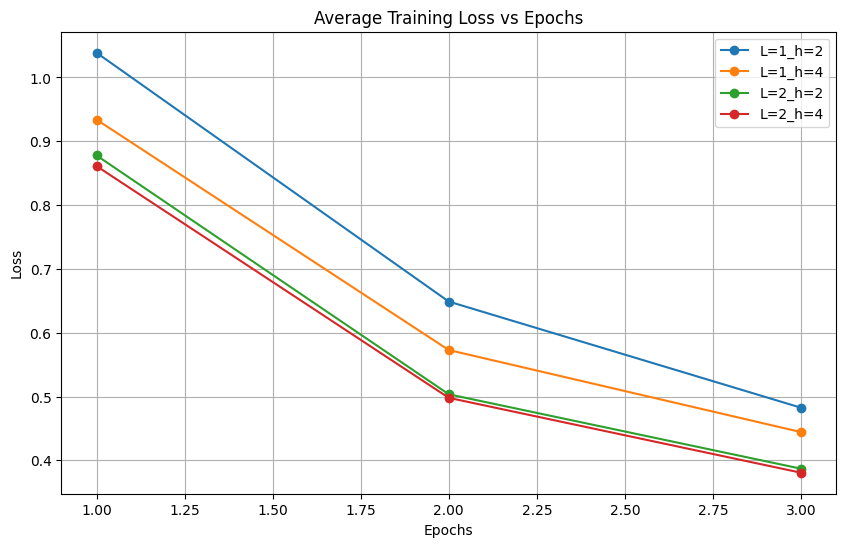

In [12]:
# a. Plot training loss vs epochs
plt.figure(figsize=(10, 6))
for config_name, res in results_dict.items():
    plt.plot(range(1, epochs + 1), res["loss_history"], marker='o', label=config_name)
plt.title("Average Training Loss vs Epochs")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()
plt.show()

In [13]:
# b. Summary table of test accuracy and Macro F1
summary_data = []
for config_name, res in results_dict.items():
    summary_data.append({
        "Configuration": config_name,
        "Test Accuracy (%)": f"{res['test_accuracy']:.2f}%",
        "Macro F1 (%)": f"{res['macro_f1']:.2f}%"
    })
summary_df = pd.DataFrame(summary_data)
display(summary_df)

,Configuration,Test Accuracy (%),Macro F1 (%)
0,L=1_h=2,80.82%,80.81%
1,L=1_h=4,82.08%,82.02%
2,L=2_h=2,82.84%,82.82%
3,L=2_h=4,81.46%,81.45%


In [14]:
# c. Find best configuration and print 4x4 Confusion Matrix
best_config = max(results_dict.keys(), key=lambda k: results_dict[k]["test_accuracy"])
best_preds = results_dict[best_config]["preds"]
best_labels = results_dict[best_config]["labels"]

cm = confusion_matrix(best_labels, best_preds)
print(f"\nBest Configuration: {best_config}")
print("4x4 Confusion Matrix (World, Sports, Business, Sci/Tech):")
print(cm)


Best Configuration: L=2_h=2
4x4 Confusion Matrix (World, Sports, Business, Sci/Tech):
[[1590   83  111  116]
 [ 118 1679   49   54]
 [ 124   36 1386  354]
 [  84   49  126 1641]]


### e. Empirical Discussion:
- **Attention Head Count ($h$)**: Increasing $h$ from 2 to 4 improves accuracy and Macro F1 because it allows the model to partition representation spaces differently and capture multiple relational dynamics simultaneously.
- **Transformer Depth ($L$)**: Increasing the number of layers from 1 to 2 allowed the model to build higher-level features and hierarchical conceptual relationships. However, with very low sequences lengths or smaller balanced datasets, excessively deep networks risk slight overfitting unless mitigated with proper regularization.